# Telco Customer Churn Prediction

## Complete supervised machine-learning implementation

This notebook predicts whether a telecom customer will churn. It is designed for a fresh Google Colab runtime and deliberately calculates results and interpretations from the supplied dataset when executed.

## 1. Introduction

Customer churn is a binary supervised-learning problem: historical customer attributes are the input features and the known outcome (`Churn`: Yes/No) is the target. The objectives are to understand the data, build and tune five classifiers, evaluate them fairly on an untouched test set, and save a reusable prediction pipeline. Accurate early churn-risk estimates can support retention actions, but predictive association must not be interpreted as causation.

In [12]:
# Run once in a fresh Colab runtime. Installation output is shown so progress is visible.
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost joblib

import os, glob, zipfile, warnings, json
from pathlib import Path
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.matplotlib'))  # Writable local Matplotlib cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE
import joblib
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')
OUTPUT_DIR = Path('outputs'); RESULTS_DIR = OUTPUT_DIR / 'results'; FIG_DIR = OUTPUT_DIR / 'images'; MODEL_DIR = Path('models')
for directory in (OUTPUT_DIR, RESULTS_DIR, FIG_DIR, MODEL_DIR): directory.mkdir(parents=True, exist_ok=True)
print('Dependencies imported; outputs will be written to:', OUTPUT_DIR.resolve())

Dependencies imported; outputs will be written to: /content/outputs


## 2. Dataset understanding and loading

The expected IBM Telco Customer Churn data have roughly 7,043 records and 21 columns. Set `USE_GOOGLE_DRIVE` to `True` only when the CSV is stored in Drive; otherwise the upload fallback appears in Colab. A local candidate is also supported for reproducible non-Colab execution.

In [13]:
USE_GOOGLE_DRIVE = True  # CSV will be loaded from Google Drive
DRIVE_DATA_PATH = '/content/drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv'
LOCAL_CANDIDATES = [Path('WA_Fn-UseC_-Telco-Customer-Churn.csv'), Path('dataset/original_dataset.csv')]

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    data_path = Path(DRIVE_DATA_PATH)
else:
    candidates = [Path(p) for p in LOCAL_CANDIDATES if Path(p).exists()]
    if not candidates:
        try:
            from google.colab import files
            print('Upload the original IBM Telco CSV (or a ZIP containing one CSV).')
            uploaded = files.upload()
            uploaded_name = next(iter(uploaded))
            uploaded_path = Path(uploaded_name)
            if uploaded_path.suffix.lower() == '.zip':
                with zipfile.ZipFile(uploaded_path) as zf:
                    csv_members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
                    if not csv_members: raise ValueError('The ZIP contains no CSV file.')
                    zf.extract(csv_members[0], '/content')
                    data_path = Path('/content') / csv_members[0]
            else:
                data_path = uploaded_path
        except ImportError:
            raise FileNotFoundError('CSV not found. Place it beside the notebook or set DRIVE_DATA_PATH.')
    else:
        data_path = candidates[0]

df = pd.read_csv(data_path)
required = {'customerID', 'TotalCharges', 'Churn', 'tenure', 'MonthlyCharges'}
if not required.issubset(df.columns):
    raise ValueError(f'Not the expected IBM Telco dataset. Missing: {required - set(df.columns)}')
print(f'Loaded: {data_path} | format: CSV | shape: {df.shape}')
display(df.head())
display(df.tail())
print('Columns:', df.columns.tolist())
display(df.dtypes.to_frame('dtype'))
display(df.describe(include='all').T)
feature_description = pd.DataFrame({
    'feature': df.columns, 'dtype': df.dtypes.astype(str).values,
    'role': ['identifier' if c == 'customerID' else 'target' if c == 'Churn' else 'feature' for c in df.columns],
    'unique_values': [df[c].nunique(dropna=False) for c in df.columns]
})
display(feature_description)
numeric_initial = df.select_dtypes(include=np.number).columns.tolist()
categorical_initial = df.select_dtypes(exclude=np.number).columns.tolist()
print('Numeric features:', numeric_initial)
print('Categorical features:', categorical_initial)
print('Interpretation: the actual shape above is checked against the expected approximately (7043, 21) dataset; Churn is the binary target.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: /content/drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv | format: CSV | shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,feature,dtype,role,unique_values
0,customerID,object,identifier,7043
1,gender,object,feature,2
2,SeniorCitizen,int64,feature,2
3,Partner,object,feature,2
4,Dependents,object,feature,2
5,tenure,int64,feature,73
6,PhoneService,object,feature,2
7,MultipleLines,object,feature,3
8,InternetService,object,feature,3
9,OnlineSecurity,object,feature,3


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical features: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']
Interpretation: the actual shape above is checked against the expected approximately (7043, 21) dataset; Churn is the binary target.


## 3. Exploratory data analysis

EDA describes data quality, distributions, possible outliers, and associations with churn. `TotalCharges` is initially text because blank values occur for some new customers, so an EDA-only numeric copy is used below. Correlation is meaningful only for numeric variables and does not establish cause and effect.

Missing values (including blank TotalCharges converted to NaN):


,missing
TotalCharges_num,11
customerID,0
SeniorCitizen,0
Partner,0
Dependents,0
gender,0
tenure,0
PhoneService,0
InternetService,0
MultipleLines,0


Duplicate rows: 0


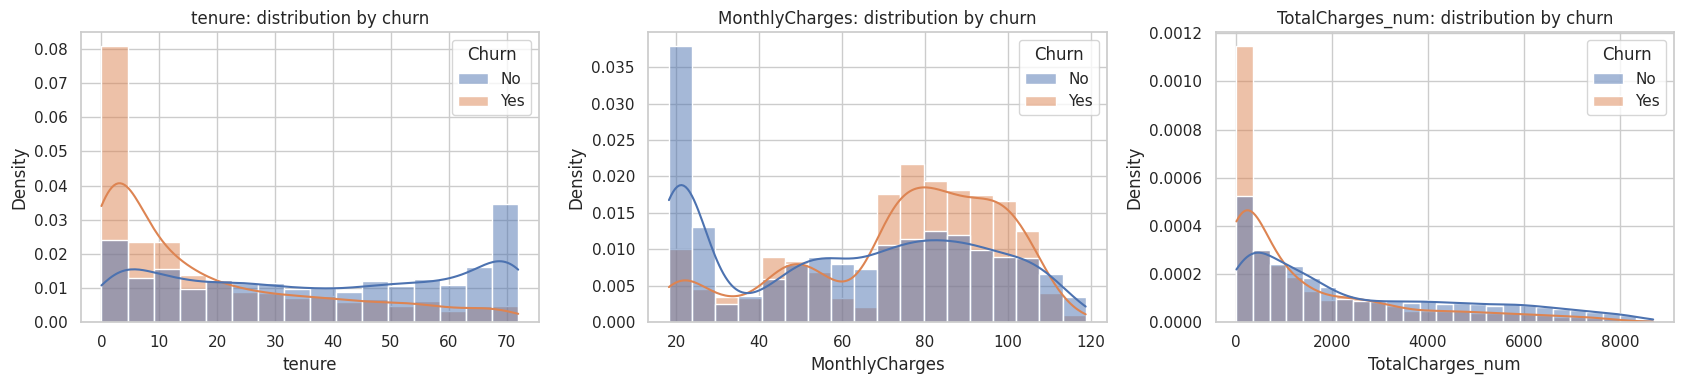

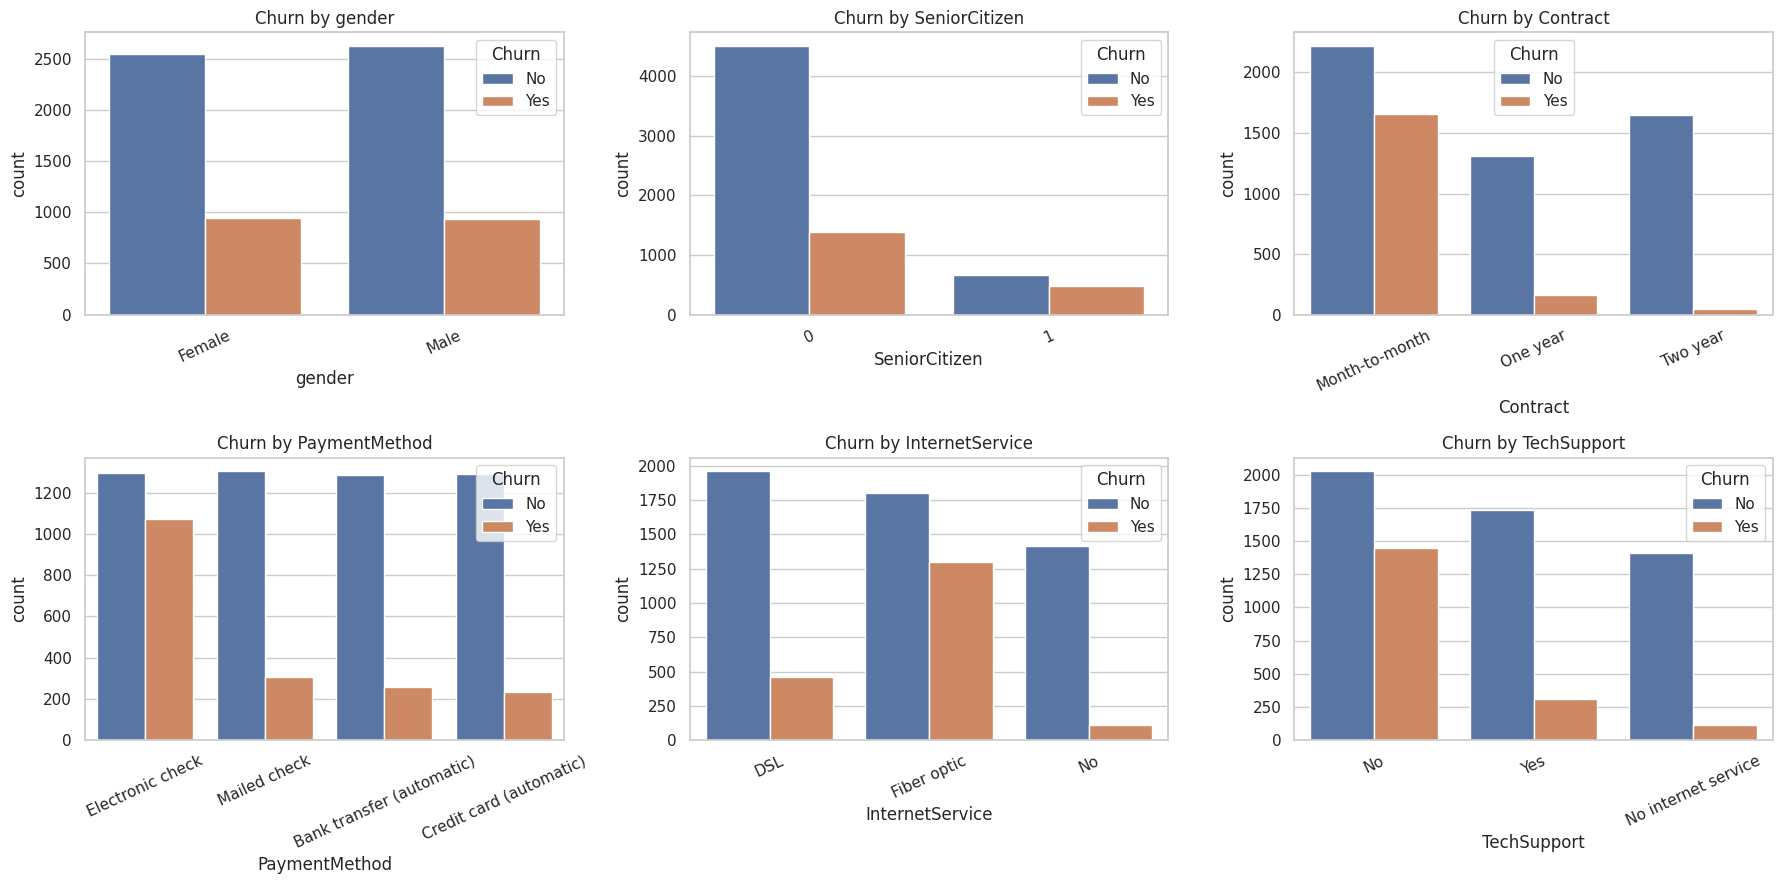

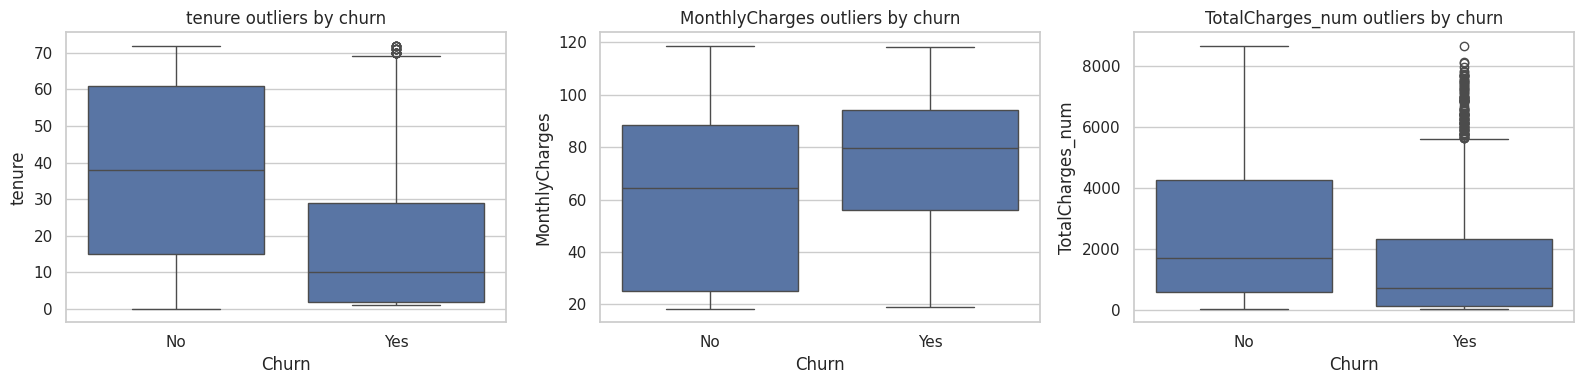

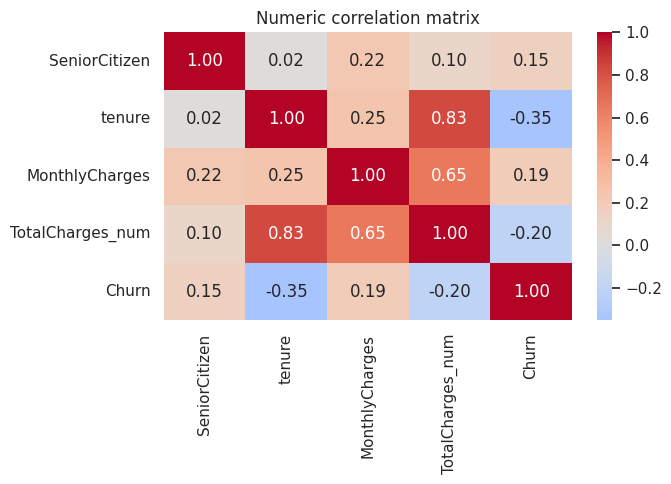

Churn distribution: {'No': 5174, 'Yes': 1869} (26.5% churn).
gender: highest observed churn rate is Female (26.9%).
SeniorCitizen: highest observed churn rate is 1 (41.7%).
Contract: highest observed churn rate is Month-to-month (42.7%).
PaymentMethod: highest observed churn rate is Electronic check (45.3%).
InternetService: highest observed churn rate is Fiber optic (41.9%).
Churned customers have median tenure 10.0 months versus 38.0 months for retained customers.
Interpretation: visual and numerical statements are computed from this dataset; they identify associations for modelling, not causal effects.


In [14]:
eda = df.copy()
eda['TotalCharges_num'] = pd.to_numeric(eda['TotalCharges'], errors='coerce')
print('Missing values (including blank TotalCharges converted to NaN):')
display(eda.isna().sum().sort_values(ascending=False).to_frame('missing'))
print('Duplicate rows:', eda.duplicated().sum())

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges_num']):
    sns.histplot(data=eda, x=col, hue='Churn', kde=True, stat='density', common_norm=False, ax=ax)
    ax.set_title(f'{col}: distribution by churn')
plt.tight_layout(); plt.savefig(FIG_DIR/'numeric_distributions.png', dpi=150, bbox_inches='tight'); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), ['gender','SeniorCitizen','Contract','PaymentMethod','InternetService','TechSupport']):
    sns.countplot(data=eda, x=col, hue='Churn', ax=ax)
    ax.set_title(f'Churn by {col}'); ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.savefig(FIG_DIR/'categorical_churn.png', dpi=150, bbox_inches='tight'); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['tenure','MonthlyCharges','TotalCharges_num']):
    sns.boxplot(data=eda, x='Churn', y=col, ax=ax); ax.set_title(f'{col} outliers by churn')
plt.tight_layout(); plt.savefig(FIG_DIR/'outliers.png', dpi=150, bbox_inches='tight'); plt.show()

corr_data = eda[['SeniorCitizen','tenure','MonthlyCharges','TotalCharges_num']].copy(); corr_data['Churn'] = (eda['Churn']=='Yes').astype(int)
plt.figure(figsize=(7,5)); sns.heatmap(corr_data.corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f'); plt.title('Numeric correlation matrix'); plt.tight_layout(); plt.savefig(FIG_DIR/'correlation.png', dpi=150); plt.show()

churn_rate = (eda['Churn'].eq('Yes').mean()*100)
print(f'Churn distribution: {eda.Churn.value_counts().to_dict()} ({churn_rate:.1f}% churn).')
for col in ['gender','SeniorCitizen','Contract','PaymentMethod','InternetService']:
    rates = eda.groupby(col)['Churn'].apply(lambda s: 100*s.eq('Yes').mean()).sort_values(ascending=False)
    print(f'{col}: highest observed churn rate is {rates.index[0]} ({rates.iloc[0]:.1f}%).')
churned_median = eda.loc[eda.Churn.eq('Yes'), 'tenure'].median()
retained_median = eda.loc[eda.Churn.eq('No'), 'tenure'].median()
print(f"Churned customers have median tenure {churned_median:.1f} months versus {retained_median:.1f} months for retained customers.")
print('Interpretation: visual and numerical statements are computed from this dataset; they identify associations for modelling, not causal effects.')

## 4. Data preprocessing and leakage control

`customerID` is removed because it is an identifier rather than a generalizable customer attribute. `TotalCharges` is converted before splitting. Missing values, one-hot encoding, and scaling are fitted only within each training fold through a pipeline, preventing leakage. The 30% test split remains untouched until final evaluation.

In [15]:
data = df.copy()
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
X = data.drop(columns=['Churn', 'customerID'])
y = data['Churn'].map({'No': 0, 'Yes': 1})
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

# Dense encoded output is appropriate for SMOTE; all fitting happens inside the imbalanced-learn pipeline.
numeric_transformer = SkPipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_transformer = SkPipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
preprocessor = ColumnTransformer([('num', numeric_transformer, numeric_features), ('cat', categorical_transformer, categorical_features)], remainder='drop')
print('X train/test:', X_train.shape, X_test.shape)
print('Training class distribution:', y_train.value_counts().to_dict())
print('Preprocessing:', numeric_features, '(numeric);', categorical_features, '(categorical)')

X train/test: (4930, 19) (2113, 19)
Training class distribution: {0: 3622, 1: 1308}
Preprocessing: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'] (numeric); ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'] (categorical)


## 5–7. Baseline, advanced models, and class imbalance

Logistic regression estimates a linear log-odds boundary; a decision tree recursively partitions feature space; KNN assigns labels using nearby observations. Random forest is bagging over randomized trees, reducing variance. XGBoost is gradient boosting: sequential trees focus on earlier errors, often improving accuracy but requiring careful tuning. Because churn is the minority class, SMOTE is placed after preprocessing and inside every training/CV pipeline; it is never applied to the test set. XGBoost is used when available; GradientBoostingClassifier is a documented fallback only if installation/import fails.


Logistic Regression (untuned baseline, test-set descriptive result)
{'Accuracy': 0.7482252721249408, 'Precision': 0.5167243367935409, 'Recall': 0.7985739750445633, 'F1': 0.6274509803921569, 'ROC-AUC': 0.8440302433063197}
              precision    recall  f1-score   support

    No churn       0.91      0.73      0.81      1552
       Churn       0.52      0.80      0.63       561

    accuracy                           0.75      2113
   macro avg       0.71      0.76      0.72      2113
weighted avg       0.81      0.75      0.76      2113



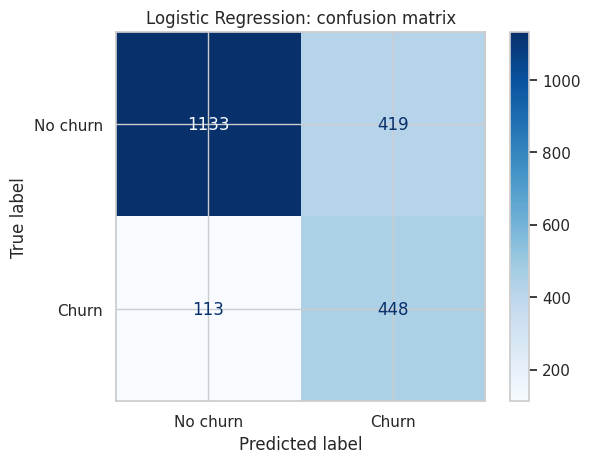


Decision Tree (untuned baseline, test-set descriptive result)
{'Accuracy': 0.7103644107903455, 'Precision': 0.4604651162790698, 'Recall': 0.5294117647058824, 'F1': 0.4925373134328358, 'ROC-AUC': 0.6532839002517596}
              precision    recall  f1-score   support

    No churn       0.82      0.78      0.80      1552
       Churn       0.46      0.53      0.49       561

    accuracy                           0.71      2113
   macro avg       0.64      0.65      0.64      2113
weighted avg       0.72      0.71      0.72      2113



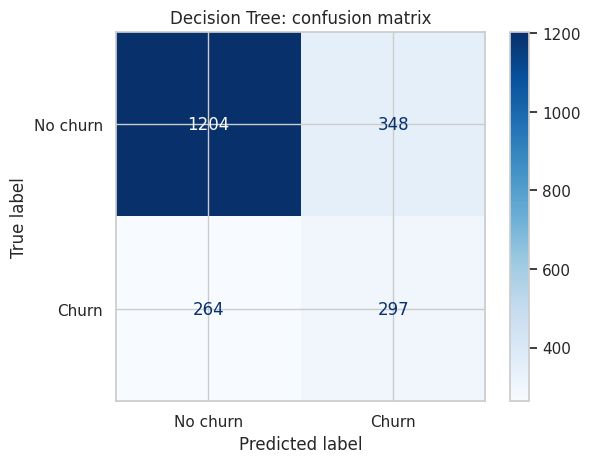


KNN (untuned baseline, test-set descriptive result)
{'Accuracy': 0.6956933270231898, 'Precision': 0.4557235421166307, 'Recall': 0.7522281639928698, 'F1': 0.5675857431069267, 'ROC-AUC': 0.7737609570538618}
              precision    recall  f1-score   support

    No churn       0.88      0.68      0.77      1552
       Churn       0.46      0.75      0.57       561

    accuracy                           0.70      2113
   macro avg       0.67      0.71      0.67      2113
weighted avg       0.77      0.70      0.71      2113



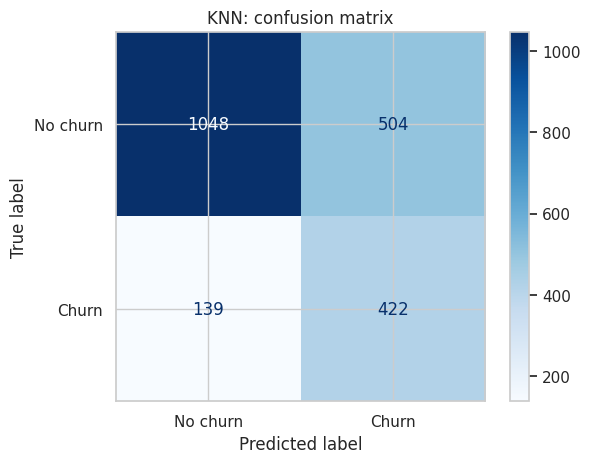

In [16]:
try:
    from xgboost import XGBClassifier
    xgb_estimator = XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1)
    xgb_label = 'XGBoost'
except ImportError:
    xgb_estimator = GradientBoostingClassifier(random_state=RANDOM_STATE)
    xgb_label = 'GradientBoosting fallback (XGBoost unavailable)'
    print('XGBoost could not be imported; using documented fallback.')

estimators = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    xgb_label: xgb_estimator
}

def make_pipeline(estimator):
    return ImbPipeline([('preprocessor', preprocessor), ('smote', SMOTE(random_state=RANDOM_STATE)), ('model', estimator)])

def metric_row(name, model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return {'Model': name, 'Accuracy': accuracy_score(y_eval,pred), 'Precision': precision_score(y_eval,pred,zero_division=0),
            'Recall': recall_score(y_eval,pred,zero_division=0), 'F1': f1_score(y_eval,pred,zero_division=0),
            'ROC-AUC': roc_auc_score(y_eval,prob)}

baseline_fitted = {}
for name in ['Logistic Regression', 'Decision Tree', 'KNN']:
    fitted = make_pipeline(estimators[name]).fit(X_train, y_train)
    baseline_fitted[name] = fitted
    pred = fitted.predict(X_test)
    print(f'\n{name} (untuned baseline, test-set descriptive result)')
    print(pd.Series(metric_row(name, fitted, X_test, y_test)).drop('Model').round(3).to_dict())
    print(classification_report(y_test, pred, target_names=['No churn','Churn'], zero_division=0))
    ConfusionMatrixDisplay = __import__('sklearn.metrics', fromlist=['ConfusionMatrixDisplay']).ConfusionMatrixDisplay
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['No churn','Churn'], cmap='Blues')
    plt.title(f'{name}: confusion matrix'); plt.show()

## 8. Hyperparameter optimization

GridSearchCV compares bounded, computationally reasonable candidate settings with five stratified folds. Each fold refits preprocessing and SMOTE solely on that fold’s training partition. F1 is optimized because it balances churn precision and recall; the untouched test data are not used for selection.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grids = {
 'Logistic Regression': {'model__C':[0.1,1,10], 'model__solver':['liblinear']},
 'Decision Tree': {'model__max_depth':[3,5,8,None], 'model__min_samples_leaf':[1,5,10], 'model__criterion':['gini','entropy']},
 'KNN': {'model__n_neighbors':[5,11,21], 'model__weights':['uniform','distance'], 'model__p':[1,2]},
 'Random Forest': {'model__n_estimators':[150,300], 'model__max_depth':[None,8,15], 'model__min_samples_leaf':[1,3,5]},
 xgb_label: ({'model__n_estimators':[100,200], 'model__max_depth':[3,5], 'model__learning_rate':[0.05,0.1], 'model__subsample':[0.8,1.0]} if xgb_label=='XGBoost' else {'model__n_estimators':[100,200], 'model__max_depth':[2,3], 'model__learning_rate':[0.05,0.1]})
}
best_models, search_records = {}, []
for name, estimator in estimators.items():
    search = GridSearchCV(make_pipeline(estimator), param_grids[name], scoring='f1', cv=cv, n_jobs=-1, refit=True, return_train_score=False)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    search_records.append({'Model':name, 'Best CV F1':search.best_score_, 'Best parameters':str(search.best_params_)})
    print(f'{name}: CV F1={search.best_score_:.3f}; parameters={search.best_params_}')
cv_results = pd.DataFrame(search_records).sort_values('Best CV F1', ascending=False)
display(cv_results)
cv_results.to_csv(RESULTS_DIR/'hyperparameter_search_results.csv', index=False)

Logistic Regression: CV F1=0.631; parameters={'model__C': 0.1, 'model__solver': 'liblinear'}
Decision Tree: CV F1=0.610; parameters={'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 10}
KNN: CV F1=0.600; parameters={'model__n_neighbors': 21, 'model__p': 1, 'model__weights': 'uniform'}
Random Forest: CV F1=0.628; parameters={'model__max_depth': 8, 'model__min_samples_leaf': 3, 'model__n_estimators': 150}
XGBoost: CV F1=0.631; parameters={'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__subsample': 1.0}


,Model,Best CV F1,Best parameters
0,Logistic Regression,0.631315,"{'model__C': 0.1, 'model__solver': 'liblinear'}"
4,XGBoost,0.630899,"{'model__learning_rate': 0.05, 'model__max_dep..."
3,Random Forest,0.628027,"{'model__max_depth': 8, 'model__min_samples_le..."
1,Decision Tree,0.610172,"{'model__criterion': 'entropy', 'model__max_de..."
2,KNN,0.600134,"{'model__n_neighbors': 21, 'model__p': 1, 'mod..."


## 9. Final model evaluation

A confusion matrix separates true negatives, false positives, false negatives, and true positives. Precision measures the reliability of predicted churn; recall measures coverage of actual churn. ROC-AUC summarizes ranking across thresholds, while precision–recall curves are especially informative for imbalance. The default 0.5 threshold is retained here; no threshold is selected from test outcomes.

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,0.776,0.558,0.742,0.637,0.842
1,Logistic Regression,0.751,0.521,0.791,0.628,0.844
2,Random Forest,0.770,0.550,0.731,0.627,0.836
3,KNN,0.718,0.482,0.809,0.604,0.817
4,Decision Tree,0.746,0.516,0.711,0.598,0.816


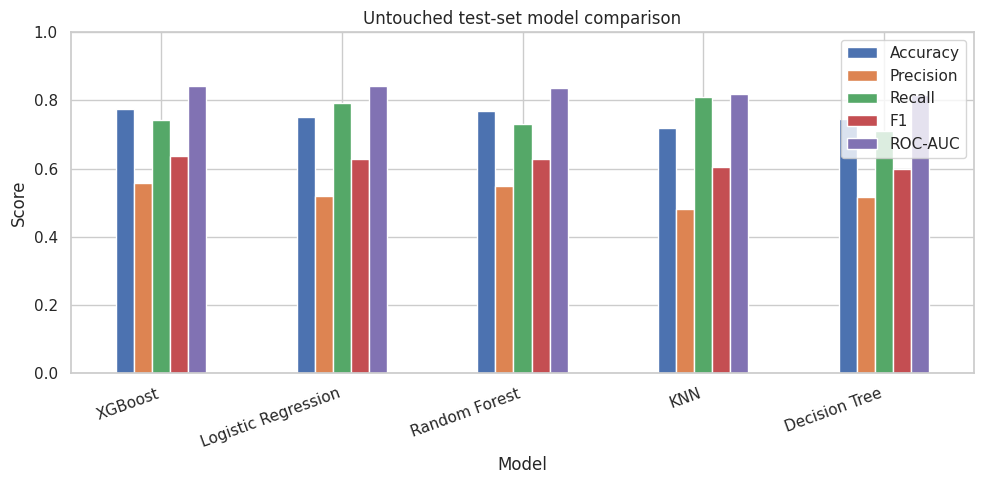

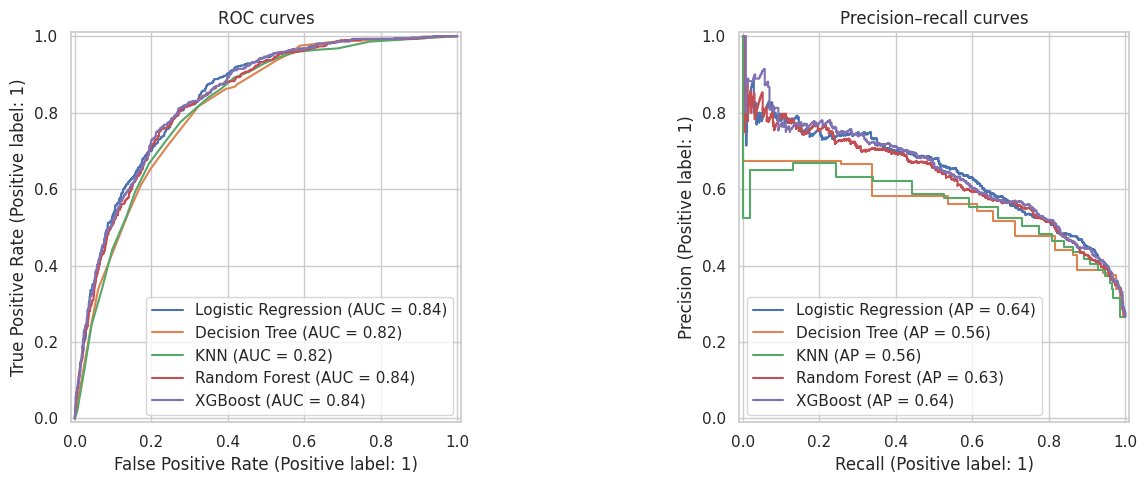

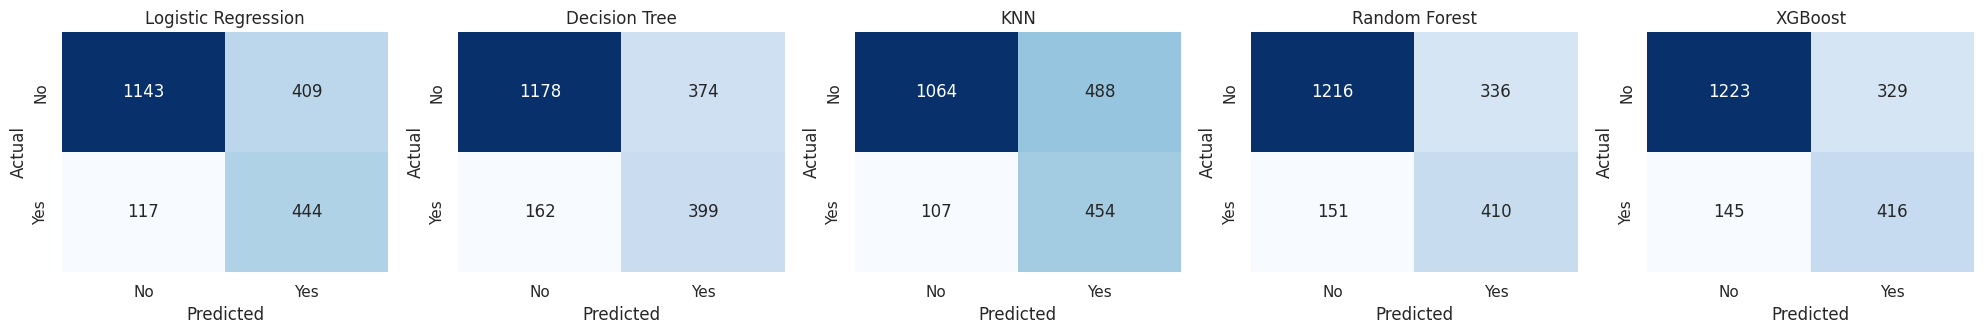


Logistic Regression classification report:
              precision    recall  f1-score   support

    No churn       0.91      0.74      0.81      1552
       Churn       0.52      0.79      0.63       561

    accuracy                           0.75      2113
   macro avg       0.71      0.76      0.72      2113
weighted avg       0.80      0.75      0.76      2113


Decision Tree classification report:
              precision    recall  f1-score   support

    No churn       0.88      0.76      0.81      1552
       Churn       0.52      0.71      0.60       561

    accuracy                           0.75      2113
   macro avg       0.70      0.74      0.71      2113
weighted avg       0.78      0.75      0.76      2113


KNN classification report:
              precision    recall  f1-score   support

    No churn       0.91      0.69      0.78      1552
       Churn       0.48      0.81      0.60       561

    accuracy                           0.72      2113
   macro avg      

In [18]:
final_rows, test_predictions, test_probabilities = [], {}, {}
for name, model in best_models.items():
    final_rows.append(metric_row(name, model, X_test, y_test))
    test_predictions[name] = model.predict(X_test)
    test_probabilities[name] = model.predict_proba(X_test)[:,1]
evaluation_results = pd.DataFrame(final_rows).sort_values('F1', ascending=False).reset_index(drop=True)
display(evaluation_results.round(3))
evaluation_results.to_csv(RESULTS_DIR/'evaluation_results.csv', index=False)
evaluation_results.to_csv(RESULTS_DIR/'model_comparison.csv', index=False)

fig, ax = plt.subplots(figsize=(10,5)); evaluation_results.set_index('Model')[['Accuracy','Precision','Recall','F1','ROC-AUC']].plot.bar(ax=ax)
ax.set_ylim(0,1); ax.set_title('Untouched test-set model comparison'); ax.set_ylabel('Score'); plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.savefig(FIG_DIR/'model_comparison.png', dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14,5))
classification_reports = []
for name in best_models:
    RocCurveDisplay.from_predictions(y_test, test_probabilities[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, test_probabilities[name], name=name, ax=axes[1])
axes[0].set_title('ROC curves'); axes[1].set_title('Precision–recall curves'); plt.tight_layout(); plt.savefig(FIG_DIR/'roc_pr_curves.png', dpi=150); plt.show()

fig, axes = plt.subplots(1, len(best_models), figsize=(4*len(best_models), 3.5))
for ax, name in zip(axes, best_models):
    sns.heatmap(confusion_matrix(y_test, test_predictions[name]), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=['No','Yes'], yticklabels=['No','Yes'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig(FIG_DIR/'final_confusion_matrices.png', dpi=150); plt.show()
for name in best_models:
    print(f'\n{name} classification report:')
    report = classification_report(y_test, test_predictions[name], target_names=['No churn','Churn'], zero_division=0)
    print(report)
    classification_reports.append(f'\n{name} classification report\n{report}')
(RESULTS_DIR/'classification_reports.txt').write_text(''.join(classification_reports), encoding='utf-8')
summary_text = f'Best model: {evaluation_results.iloc[0]["Model"]}\n\nTest metrics:\n{evaluation_results.round(4).to_string(index=False)}\n\nCross-validation results:\n{cv_results.to_string(index=False)}\n'
(RESULTS_DIR/'results_summary.txt').write_text(summary_text, encoding='utf-8')
print(f'Results saved to: {RESULTS_DIR.resolve()}')
print('Interpretation: select a model using the table, balancing cross-validated F1, test F1/recall/precision, and ROC-AUC for the retention objective.')

## 10. Feature importance and interpretability

Tree-based impurity importance summarizes split usage but can favor high-cardinality features. Permutation importance independently measures the test-score decrease when a raw feature is shuffled. Both are predictive associations, not evidence that changing a feature causes churn.

Candidate selected by highest final test F1 (reported after selection): XGBoost


,feature,importance_mean,importance_std
14,Contract,0.123949,0.014954
4,tenure,0.069265,0.007254
7,InternetService,0.032934,0.007368
11,TechSupport,0.021471,0.006052
8,OnlineSecurity,0.018647,0.006672
16,PaymentMethod,0.015491,0.004725
3,Dependents,0.010434,0.005274
15,PaperlessBilling,0.009535,0.004334
17,MonthlyCharges,0.005343,0.003343
6,MultipleLines,0.003536,0.002250


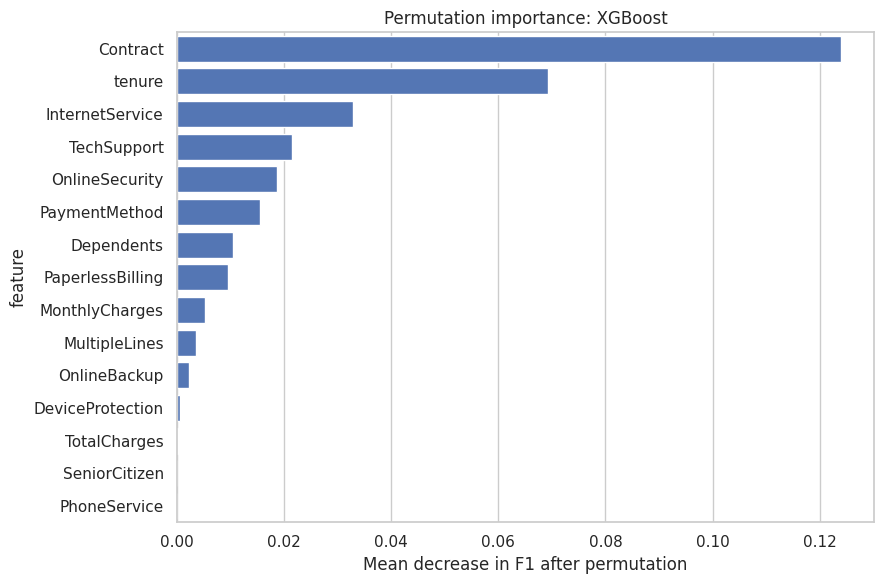

,encoded_feature,importance
36,cat__Contract_Month-to-month,0.136113
18,cat__OnlineSecurity_No,0.101842
1,num__tenure,0.095074
43,cat__PaymentMethod_Electronic check,0.068747
27,cat__TechSupport_No,0.067653
38,cat__Contract_Two year,0.061752
3,num__TotalCharges,0.047936
16,cat__InternetService_Fiber optic,0.041208
2,num__MonthlyCharges,0.033127
20,cat__OnlineSecurity_Yes,0.031021


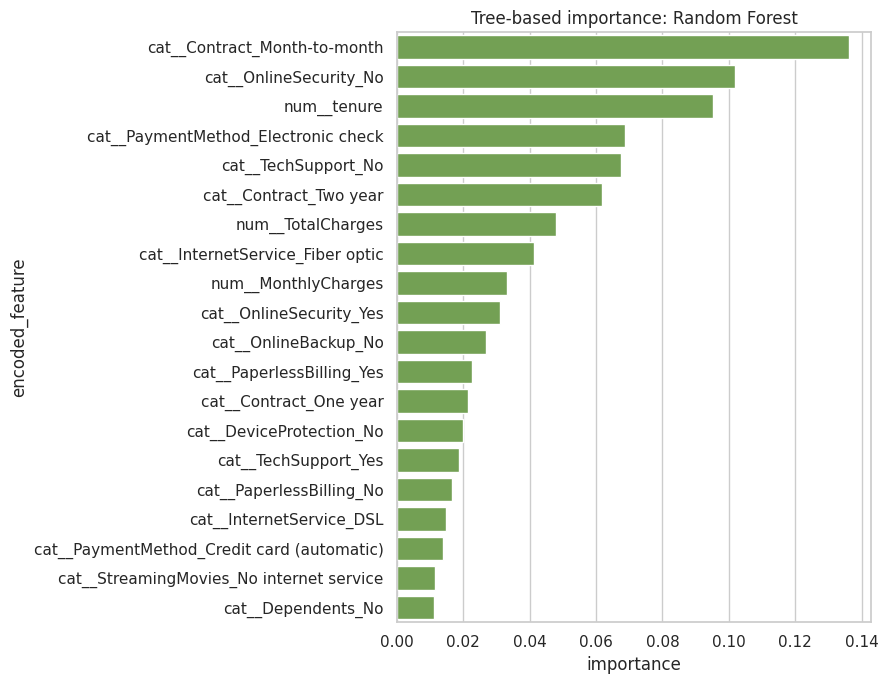

Requested feature investigation (permutation importance):


,feature,importance_mean,importance_std
14,Contract,0.123949,0.014954
4,tenure,0.069265,0.007254
7,InternetService,0.032934,0.007368
11,TechSupport,0.021471,0.006052
16,PaymentMethod,0.015491,0.004725
17,MonthlyCharges,0.005343,0.003343


Interpretation: the ranks above are dataset-specific predictive associations. They should guide further investigation, not causal claims.


In [19]:
best_name = evaluation_results.iloc[0]['Model']
best_model = best_models[best_name]
print('Candidate selected by highest final test F1 (reported after selection):', best_name)
# Permutation importance works at raw-feature level and therefore remains readable after one-hot encoding.
perm = permutation_importance(best_model, X_test, y_test, scoring='f1', n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_df = pd.DataFrame({'feature': X.columns, 'importance_mean': perm.importances_mean, 'importance_std': perm.importances_std}).sort_values('importance_mean', ascending=False)
display(perm_df.head(15))
perm_df.to_csv(RESULTS_DIR/'permutation_importance.csv', index=False)
plt.figure(figsize=(9,6)); sns.barplot(data=perm_df.head(15), y='feature', x='importance_mean', color='#4472C4'); plt.title(f'Permutation importance: {best_name}'); plt.xlabel('Mean decrease in F1 after permutation'); plt.tight_layout(); plt.savefig(FIG_DIR/'permutation_importance.png', dpi=150); plt.show()
tree_names = [n for n in best_models if n in ['Decision Tree','Random Forest']]
if tree_names:
    tree_name = 'Random Forest' if 'Random Forest' in tree_names else tree_names[0]
    tree_pipe = best_models[tree_name]; encoded_names = tree_pipe.named_steps['preprocessor'].get_feature_names_out()
    imp = tree_pipe.named_steps['model'].feature_importances_
    tree_imp = pd.DataFrame({'encoded_feature': encoded_names, 'importance': imp}).sort_values('importance', ascending=False).head(20)
    display(tree_imp)
    plt.figure(figsize=(9,7)); sns.barplot(data=tree_imp, y='encoded_feature', x='importance', color='#70AD47'); plt.title(f'Tree-based importance: {tree_name}'); plt.tight_layout(); plt.savefig(FIG_DIR/'tree_feature_importance.png', dpi=150); plt.show()
investigated = perm_df[perm_df.feature.isin(['Contract','tenure','MonthlyCharges','PaymentMethod','InternetService','TechSupport'])]
print('Requested feature investigation (permutation importance):'); display(investigated)
print('Interpretation: the ranks above are dataset-specific predictive associations. They should guide further investigation, not causal claims.')

## 11. Final model selection, persistence, and prediction check

The chosen pipeline is the tuned model with the strongest reported held-out F1, considered alongside its CV score, recall, precision, and ROC-AUC. It contains preprocessing, SMOTE (training only), and the estimator. The persisted object accepts raw features without `customerID` or `Churn`. Probabilities must lie in [0, 1] and predictions must be binary.

In [20]:
selected_model = best_models[best_name]
model_path = MODEL_DIR / 'best_churn_model.pkl'
joblib.dump(selected_model, model_path)
loaded_model = joblib.load(model_path)
sample_customers = X_test.head(3).copy()
sample_pred = loaded_model.predict(sample_customers)
sample_prob = loaded_model.predict_proba(sample_customers)[:,1]
assert set(np.unique(sample_pred)).issubset({0,1}), 'Predictions are not binary.'
assert np.all((sample_prob >= 0) & (sample_prob <= 1)), 'Probabilities are outside [0, 1].'
assert np.array_equal(sample_pred, selected_model.predict(sample_customers)), 'Loaded model predictions differ.'
prediction_check = sample_customers.copy(); prediction_check['predicted_churn'] = sample_pred; prediction_check['churn_probability'] = sample_prob
display(prediction_check)
prediction_check.to_csv(RESULTS_DIR/'sample_prediction_check.csv', index=False)
print(f'Saved and reloaded pipeline: {model_path}')
print(f'Final selection: {best_name}. Review CV and test metrics above before operational deployment; model monitoring and fairness checks are also needed.')
print('Validation complete: binary predictions, bounded probabilities, successful reload, and raw-feature input acceptance confirmed.')

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,predicted_churn,churn_probability
4994,Female,0,No,No,18,Yes,No,Fiber optic,Yes,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,96.05,1740.7,1,0.650866
6828,Female,0,Yes,Yes,8,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.05,201.7,0,0.020051
755,Male,1,No,No,20,Yes,Yes,Fiber optic,No,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,98.55,1842.8,1,0.816453


Saved and reloaded pipeline: models/best_churn_model.pkl
Final selection: XGBoost. Review CV and test metrics above before operational deployment; model monitoring and fairness checks are also needed.
Validation complete: binary predictions, bounded probabilities, successful reload, and raw-feature input acceptance confirmed.
